# 📊 Google Colab + Kaggle + SQL
## Opérations CRUD Complètes avec Données Réelles

---

### 🎯 Objectifs de ce Notebook
- Télécharger un dataset Kaggle
- Décrire la structure de la base de données
- Tester des requêtes INSERT
- Tester des requêtes SELECT
- Tester des requêtes UPDATE
- Tester des requêtes DELETE

**Temps estimé:** 15-20 minutes

---

correction des réponses des exercices texte en gras 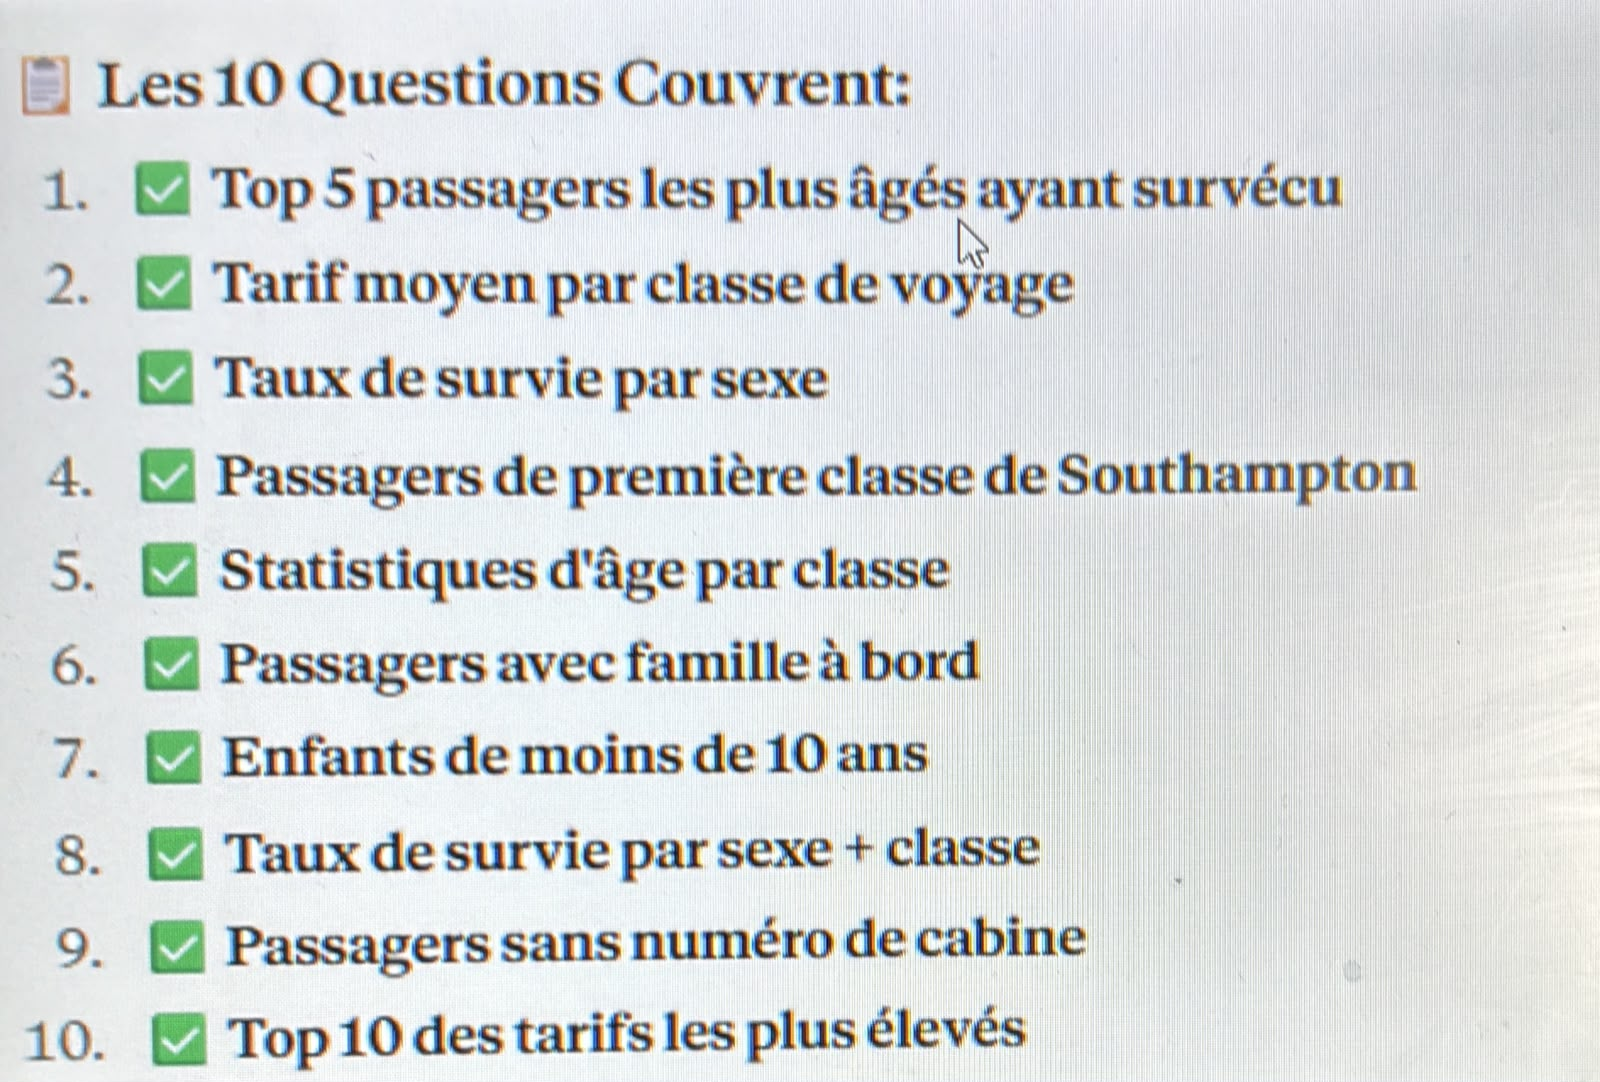

## Section 1: Installation des Dépendances

Installez automatiquement tous les packages nécessaires.

In [ ]:
# Installation des dépendances
import subprocess
import sys
import os

# Désactiver temporairement l'authentification automatique lors de l'import
os.environ['KAGGLE_CONFIG_DIR'] = os.path.expanduser('~/.kaggle')

packages = ['kaggle', 'pandas', 'numpy', 'matplotlib', 'seaborn']

print("Installation des dépendances...\n")

for package in packages:
    try:
        if package == 'kaggle':
            # Pour kaggle, on vérifie via pip ou import sans déclencher l'authentification immédiate
            import importlib.util
            spec = importlib.util.find_spec(package)
            if spec is None:
                raise ImportError
        else:
            __import__(package)
        print(f"✓ {package} est déjà installé")
    except (ImportError, NameError):
        print(f"Installation de {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])
        print(f"✓ {package} installé")

print("\n✅ Toutes les dépendances sont prêtes!")

Installation des dépendances...

✓ kaggle est déjà installé
✓ pandas est déjà installé
✓ numpy est déjà installé
✓ matplotlib est déjà installé
✓ seaborn est déjà installé

✅ Toutes les dépendances sont prêtes!


## Section 2: Configuration Kaggle

Authentifiez-vous avec votre clé API Kaggle.

In [ ]:
import os

# Définir le token API
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_d7c448a1be6881316a06187f98dcf90a'

# Puis utiliser Kaggle comme normal
from kaggle.api.kaggle_api_extended import KaggleApi
api = KaggleApi()
api.authenticate()

print("✓ Authentification réussie!")

✓ Authentification réussie!


In [ ]:
import os
import json

# Créer le dossier .kaggle
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)

# Créer le fichier avec votre token
token_data = {
    "username": "votreusername",  # À remplir avec votre username Kaggle
    "key": "KGAT_d7c448a1be6881316a06187f98dcf90a"
}

with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'w') as f:
    json.dump(token_data, f)

os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)

print("✓ kaggle.json créé!")

✓ kaggle.json créé!


In [ ]:
import os
from google.colab import files

# Configuration du répertoire Kaggle
kaggle_dir = os.path.expanduser('~/.kaggle')
if not os.path.exists(kaggle_dir):
    os.makedirs(kaggle_dir)
    print(f"✓ Dossier {kaggle_dir} créé")

# Vérifier la présence de kaggle.json
kaggle_json_path = os.path.join(kaggle_dir, 'kaggle.json')
if not os.path.exists(kaggle_json_path):
    print("\n⚠️  Fichier kaggle.json non trouvé!")
    print("\nInstructions:")
    print("1. Allez sur https://www.kaggle.com/account")
    print("2. Cliquez 'Create New API Token'")
    print("3. Téléchargez kaggle.json")
    print("4. Uploadez le fichier ci-dessous:\n")

    uploaded = files.upload()
    if 'kaggle.json' in uploaded:
        os.rename('kaggle.json', kaggle_json_path)
        os.chmod(kaggle_json_path, 0o600)
        print("\n✓ kaggle.json configuré avec succès")
else:
    print("✓ Fichier kaggle.json trouvé")

# Test d'authentification
from kaggle.api.kaggle_api_extended import KaggleApi
api = KaggleApi()
api.authenticate()
print("✓ Authentification Kaggle réussie")

✓ Fichier kaggle.json trouvé
✓ Authentification Kaggle réussie


## Section 3: Connexion Google Drive

Montez Google Drive pour sauvegarder les données.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
print("✓ Google Drive monté")

# Créer le dossier pour nos données
drive_data_dir = '/content/drive/MyDrive/Colab Datasets'
if not os.path.exists(drive_data_dir):
    os.makedirs(drive_data_dir)
    print(f"✓ Dossier créé: {drive_data_dir}")
else:
    print(f"✓ Dossier existe déjà: {drive_data_dir}")

ValueError: mount failed

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Section 4: Téléchargement du Dataset Kaggle

Téléchargez le dataset Titanic depuis Kaggle.

In [ ]:
# Téléchargement du dataset Titanic via une URL publique
import urllib.request
import os

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
destination_file = os.path.join(drive_data_dir, 'train.csv')

print(f"Téléchargement du dataset depuis l'URL publique...\n")

try:
    # Télécharger le fichier et le sauvegarder sous le nom 'train.csv'
    urllib.request.urlretrieve(url, destination_file)
    print(f"✓ Dataset téléchargé avec succès et enregistré sous : {destination_file}\n")

    # Lister les fichiers pour vérification
    print("Fichiers dans le dossier :")
    files_list = os.listdir(drive_data_dir)
    for file in files_list:
        file_path = os.path.join(drive_data_dir, file)
        if os.path.isfile(file_path):
            file_size = os.path.getsize(file_path)
            print(f"  - {file} ({file_size:,} bytes)")
except Exception as e:
    print(f"Une erreur est survenue lors du téléchargement : {str(e)}")

Téléchargement du dataset depuis l'URL publique...

✓ Dataset téléchargé avec succès et enregistré sous : /content/drive/MyDrive/Colab Datasets/train.csv

Fichiers dans le dossier :
  - titanic_database.db (0 bytes)
  - train.csv (60,302 bytes)


## Section 5: Création de la Base de Données SQLite

In [ ]:
import sqlite3
import pandas as pd

# Chemins des fichiers
db_path = os.path.join(drive_data_dir, 'titanic_database.db')
train_csv = os.path.join(drive_data_dir, 'train.csv')

# Supprimer l'ancienne base si elle existe
if os.path.exists(db_path):
    os.remove(db_path)
    print("Ancienne base de données supprimée")

# Créer la connexion
conn = sqlite3.connect(db_path)
cursor = conn.cursor()
print(f"✓ Base de données créée: {db_path}\n")

# Charger les données
df = pd.read_csv(train_csv)
print(f"✓ Données chargées: {len(df)} lignes, {len(df.columns)} colonnes\n")

# Créer la table
table_name = 'passengers'
df.to_sql(table_name, conn, if_exists='replace', index=False)
print(f"✓ Table '{table_name}' créée dans la base de données")

Ancienne base de données supprimée
✓ Base de données créée: /content/drive/MyDrive/Colab Datasets/titanic_database.db

✓ Données chargées: 891 lignes, 12 colonnes

✓ Table 'passengers' créée dans la base de données


## Section 6: Description de la Structure de la Base de Données

In [12]:
# Informations sur la table
cursor.execute(f"PRAGMA table_info({table_name})")
columns_info = cursor.fetchall()

print("\n📋 STRUCTURE DE LA TABLE")
print("=" * 80)

columns_df = pd.DataFrame(columns_info, columns=['cid', 'name', 'type', 'notnull', 'dflt_value', 'pk'])
print(columns_df[['name', 'type', 'notnull']].to_string(index=False))

# Statistiques
print("\n\n📊 STATISTIQUES")
print("=" * 80)

cursor.execute(f"SELECT COUNT(*) FROM {table_name}")
total_rows = cursor.fetchone()[0]
print(f"Total des lignes: {total_rows:,}")

# Analyse détaillée
print("\n📈 ANALYSE PAR COLONNE")
print("=" * 80)

for col_info in columns_info[:8]:  # Afficher les 8 premières colonnes
    col_name = col_info[1]
    col_type = col_info[2]

    cursor.execute(f"SELECT COUNT(DISTINCT {col_name}) FROM {table_name} WHERE {col_name} IS NOT NULL")
    distinct_count = cursor.fetchone()[0]

    cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE {col_name} IS NULL")
    null_count = cursor.fetchone()[0]

    print(f"\n  {col_name} ({col_type}):")
    print(f"    Valeurs uniques: {distinct_count}")
    print(f"    Valeurs NULL: {null_count}")

    if col_type in ['INTEGER', 'REAL']:
        cursor.execute(f"SELECT MIN({col_name}), MAX({col_name}), AVG({col_name}) FROM {table_name}")
        min_val, max_val, avg_val = cursor.fetchone()
        if min_val is not None:
            print(f"    Min: {min_val}, Max: {max_val}, Moyenne: {avg_val:.2f}")

NameError: name 'cursor' is not defined

question 1





## Aperçu des Données

In [ ]:
print("\n📋 PREMIÈRES LIGNES DE LA TABLE")
print("=" * 80 + "\n")

query = f"SELECT * FROM {table_name} LIMIT 5"
result_df = pd.read_sql_query(query, conn)
display(result_df)

---

# 📝 OPÉRATIONS SQL

## Section 7: REQUÊTES INSERT

### 1. Insert Simple

In [ ]:
print("\n1️⃣  INSERT SIMPLE")
print("=" * 80)

new_passenger = {
    'PassengerId': 892,
    'Survived': 1,
    'Pclass': 1,
    'Name': 'Claude, Monsieur',
    'Sex': 'male',
    'Age': 35.0,
    'SibSp': 1,
    'Parch': 1,
    'Ticket': 'AI001',
    'Fare': 512.33,
    'Cabin': 'A123',
    'Embarked': 'S'
}

insert_query = f"""
INSERT INTO {table_name}
(PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
"""

values = tuple(new_passenger.values())
cursor.execute(insert_query, values)
conn.commit()

print("\n✓ Requête INSERT exécutée avec succès!")
print(f"\nDonnées insérées:")
for key, value in new_passenger.items():
    print(f"  {key}: {value}")

# Vérification
cursor.execute(f"SELECT * FROM {table_name} WHERE PassengerId = 892")
inserted_row = cursor.fetchone()
print(f"\n✓ Vérification: Ligne retrouvée dans la base de données")


1️⃣  INSERT SIMPLE

✓ Requête INSERT exécutée avec succès!

Données insérées:
  PassengerId: 892
  Survived: 1
  Pclass: 1
  Name: Claude, Monsieur
  Sex: male
  Age: 35.0
  SibSp: 1
  Parch: 1
  Ticket: AI001
  Fare: 512.33
  Cabin: A123
  Embarked: S

✓ Vérification: Ligne retrouvée dans la base de données


### 2. Insert Multiple (Bulk Insert)

In [ ]:
print("\n2️⃣  INSERT MULTIPLE (BULK INSERT)")
print("=" * 80)

new_passengers = [
    (893, 0, 3, 'Dupont, Monsieur', 'male', 25.0, 0, 0, 'AI002', 7.75, None, 'C'),
    (894, 1, 1, 'Lefevre, Madame', 'female', 28.0, 1, 1, 'AI003', 151.86, 'B5', 'S'),
    (895, 0, 2, 'Martin, Monsieur', 'male', 45.0, 0, 0, 'AI004', 10.50, None, 'Q'),
]

bulk_insert_query = f"""
INSERT INTO {table_name}
(PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
"""

cursor.executemany(bulk_insert_query, new_passengers)
conn.commit()

print("✓ Insertion en masse réussie!")
print(f"✓ {len(new_passengers)} passagers insérés\n")

print("Détail des insertions:")
for i, passenger in enumerate(new_passengers, 1):
    print(f"  Passager {i}: PassengerId={passenger[0]}, Name={passenger[3]}, Age={passenger[5]}")

# Vérifier
cursor.execute(f"SELECT COUNT(*) FROM {table_name}")
total_after = cursor.fetchone()[0]
print(f"\nTotal des lignes après insertion: {total_after:,}")


2️⃣  INSERT MULTIPLE (BULK INSERT)
✓ Insertion en masse réussie!
✓ 3 passagers insérés

Détail des insertions:
  Passager 1: PassengerId=893, Name=Dupont, Monsieur, Age=25.0
  Passager 2: PassengerId=894, Name=Lefevre, Madame, Age=28.0
  Passager 3: PassengerId=895, Name=Martin, Monsieur, Age=45.0

Total des lignes après insertion: 895


---

## Section 8: REQUÊTES SELECT

### 1. SELECT Simple

In [ ]:
print("\n1️⃣  SELECT SIMPLE")
print("=" * 80 + "\n")

query = f"SELECT * FROM {table_name} WHERE PassengerId >= 890 LIMIT 5"
print(f"Requête: {query}\n")
result_df = pd.read_sql_query(query, conn)
display(result_df)


1️⃣  SELECT SIMPLE

Requête: SELECT * FROM passengers WHERE PassengerId >= 890 LIMIT 5



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
1,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,None,Q
2,892,1,1,"Claude, Monsieur",male,35.0,1,1,AI001,512.33,A123,S
3,893,0,3,"Dupont, Monsieur",male,25.0,0,0,AI002,7.75,None,C
4,894,1,1,"Lefevre, Madame",female,28.0,1,1,AI003,151.86,B5,S


In [16]:
import sqlite3
import pandas as pd

# 1. Télécharger le dataset Titanic et créer la base
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

conn = sqlite3.connect(":memory:")
df.to_sql("passengers", conn, index=False)

def q(titre, sql):
    print(f"\n{titre}\n" + "=" * 70)
    display(pd.read_sql_query(sql, conn))

# 1. Top 5 passagers les plus âgés ayant survécu
q("1. Top 5 des plus âgés survivants", """
SELECT Name, Age, Sex, Pclass
FROM passengers
WHERE Survived = 1 AND Age IS NOT NULL
ORDER BY Age DESC
LIMIT 5""")


1. Top 5 des plus âgés survivants


,Name,Age,Sex,Pclass
0,"Barkworth, Mr. Algernon Henry Wilson",80.0,male,1
1,"Andrews, Miss. Kornelia Theodosia",63.0,female,1
2,"Turkula, Mrs. (Hedwig)",63.0,female,3
3,"Harris, Mr. George",62.0,male,2
4,"Stone, Mrs. George Nelson (Martha Evelyn)",62.0,female,1


In [17]:
# 2. Tarif moyen par classe
q("2. Tarif moyen par classe", """
SELECT Pclass AS classe, ROUND(AVG(Fare), 2) AS tarif_moyen
FROM passengers
GROUP BY Pclass
ORDER BY Pclass""")


2. Tarif moyen par classe


,classe,tarif_moyen
0,1,84.15
1,2,20.66
2,3,13.68


In [21]:

q("3. Taux de survie par sexe", """
SELECT Sex, COUNT(*) AS nb_passagers, SUM(Survived) AS survivants,
       ROUND(100.0 * SUM(Survived) / COUNT(*), 2) AS taux_survie_pct
FROM passengers
GROUP BY Sex""")


3. Taux de survie par sexe


,Sex,nb_passagers,survivants,taux_survie_pct
0,female,314,233,74.20
1,male,577,109,18.89


In [23]:

q("4. 1ère classe - Southampton", """
SELECT Name, Sex, Age, Fare
FROM passengers
WHERE Pclass = 1 AND Embarked = 'S'
ORDER BY Name""")


4. 1ère classe - Southampton


,Name,Sex,Age,Fare
0,"Allen, Miss. Elisabeth Walton",female,29.00,211.3375
1,"Allison, Master. Hudson Trevor",male,0.92,151.5500
2,"Allison, Miss. Helen Loraine",female,2.00,151.5500
3,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,151.5500
4,"Anderson, Mr. Harry",male,48.00,26.5500
...,...,...,...,...
122,"Wick, Miss. Mary Natalie",female,31.00,164.8667
123,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.00,164.8667
124,"Williams-Lambert, Mr. Fletcher Fellows",male,NaN,35.0000
125,"Woolner, Mr. Hugh",male,NaN,35.5000


In [24]:
q("5. Statistiques d'âge par classe", """
SELECT Pclass AS classe, COUNT(Age) AS nb_ages_connus,
       ROUND(AVG(Age), 2) AS age_moyen, MIN(Age) AS age_min, MAX(Age) AS age_max
FROM passengers
GROUP BY Pclass
ORDER BY Pclass""")


5. Statistiques d'âge par classe


,classe,nb_ages_connus,age_moyen,age_min,age_max
0,1,186,38.23,0.92,80.0
1,2,173,29.88,0.67,70.0
2,3,355,25.14,0.42,74.0


In [26]:
q("6. Passagers avec famille à bord", """
SELECT Name, SibSp, Parch, (SibSp + Parch) AS taille_famille
FROM passengers
WHERE SibSp + Parch > 0
ORDER BY taille_famille DESC""")


6. Passagers avec famille à bord


,Name,SibSp,Parch,taille_famille
0,"Sage, Master. Thomas Henry",8,2,10
1,"Sage, Miss. Constance Gladys",8,2,10
2,"Sage, Mr. Frederick",8,2,10
3,"Sage, Mr. George John Jr",8,2,10
4,"Sage, Miss. Stella Anna",8,2,10
...,...,...,...,...
349,"Giles, Mr. Frederick Edward",1,0,1
350,"Duran y More, Miss. Asuncion",1,0,1
351,"Abelson, Mrs. Samuel (Hannah Wizosky)",1,0,1
352,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",0,1,1


In [27]:
q("7. Enfants de moins de 10 ans", """
SELECT Name, Age, Sex, Pclass, Survived
FROM passengers
WHERE Age < 10
ORDER BY Age""")


7. Enfants de moins de 10 ans


,Name,Age,Sex,Pclass,Survived
0,"Thomas, Master. Assad Alexander",0.42,male,3,1
1,"Hamalainen, Master. Viljo",0.67,male,2,1
2,"Baclini, Miss. Helene Barbara",0.75,female,3,1
3,"Baclini, Miss. Eugenie",0.75,female,3,1
4,"Caldwell, Master. Alden Gates",0.83,male,2,1
...,...,...,...,...,...
57,"Goodwin, Master. Harold Victor",9.00,male,3,0
58,"Coutts, Master. Eden Leslie ""Neville""",9.00,male,3,1
59,"Andersson, Miss. Ingeborg Constanzia",9.00,female,3,0
60,"Skoog, Miss. Mabel",9.00,female,3,0


In [28]:
q("8. Taux de survie par sexe et classe", """
SELECT Sex, Pclass AS classe, COUNT(*) AS nb_passagers,
       ROUND(100.0 * SUM(Survived) / COUNT(*), 2) AS taux_survie_pct
FROM passengers
GROUP BY Sex, Pclass
ORDER BY Sex, Pclass""")


8. Taux de survie par sexe et classe


,Sex,classe,nb_passagers,taux_survie_pct
0,female,1,94,96.81
1,female,2,76,92.11
2,female,3,144,50.00
3,male,1,122,36.89
4,male,2,108,15.74
5,male,3,347,13.54


In [29]:
q("9. Passagers sans numéro de cabine", """
SELECT COUNT(*) AS nb_sans_cabine
FROM passengers
WHERE Cabin IS NULL OR TRIM(Cabin) = ''""")


9. Passagers sans numéro de cabine


,nb_sans_cabine
0,687


In [30]:
q("10. Top 10 des tarifs les plus élevés", """
SELECT Name, Pclass, Fare, Survived
FROM passengers
ORDER BY Fare DESC
LIMIT 10""")


10. Top 10 des tarifs les plus élevés


,Name,Pclass,Fare,Survived
0,"Ward, Miss. Anna",1,512.3292,1
1,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
2,"Lesurer, Mr. Gustave J",1,512.3292,1
3,"Fortune, Mr. Charles Alexander",1,263.0000,0
4,"Fortune, Miss. Mabel Helen",1,263.0000,1
5,"Fortune, Miss. Alice Elizabeth",1,263.0000,1
6,"Fortune, Mr. Mark",1,263.0000,0
7,"Ryerson, Miss. Emily Borie",1,262.3750,1
8,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750,1
9,"Baxter, Mr. Quigg Edmond",1,247.5208,0


### 2. SELECT avec Filtres

In [ ]:
print("\n2️⃣  SELECT AVEC FILTRES")
print("=" * 80 + "\n")

query = f"""
SELECT Name, Age, Pclass, Fare
FROM {table_name}
WHERE Age > 30 AND Survived = 1
ORDER BY Age DESC
LIMIT 10
"""

print(f"Requête: {query}\n")
result_df = pd.read_sql_query(query, conn)
print(f"Résultat: {len(result_df)} passagers trouvés\n")
display(result_df)


2️⃣  SELECT AVEC FILTRES

Requête: 
SELECT Name, Age, Pclass, Fare
FROM passengers
WHERE Age > 30 AND Survived = 1
ORDER BY Age DESC
LIMIT 10


Résultat: 10 passagers trouvés



,Name,Age,Pclass,Fare
0,"Barkworth, Mr. Algernon Henry Wilson",80.0,1,30.0000
1,"Andrews, Miss. Kornelia Theodosia",63.0,1,77.9583
2,"Turkula, Mrs. (Hedwig)",63.0,3,9.5875
3,"Harris, Mr. George",62.0,2,10.5000
4,"Stone, Mrs. George Nelson (Martha Evelyn)",62.0,1,80.0000
5,"Warren, Mrs. Frank Manley (Anna Sophia Atkinson)",60.0,1,75.2500
6,"Frolicher-Stehli, Mr. Maxmillian",60.0,1,79.2000
7,"Bonnell, Miss. Elizabeth",58.0,1,26.5500
8,"Lurette, Miss. Elise",58.0,1,146.5208
9,"Graham, Mrs. William Thompson (Edith Junkins)",58.0,1,153.4625


### 3. SELECT avec Agrégation

In [ ]:
print("\n3️⃣  SELECT AVEC AGRÉGATION")
print("=" * 80 + "\n")

query = f"""
SELECT
    Survived,
    COUNT(*) as nb_passagers,
    ROUND(AVG(Age), 2) as age_moyen,
    ROUND(AVG(Fare), 2) as fare_moyen
FROM {table_name}
GROUP BY Survived
"""

print(f"Requête: {query}\n")
result_df = pd.read_sql_query(query, conn)
display(result_df)


3️⃣  SELECT AVEC AGRÉGATION

Requête: 
SELECT
    Survived,
    COUNT(*) as nb_passagers,
    ROUND(AVG(Age), 2) as age_moyen,
    ROUND(AVG(Fare), 2) as fare_moyen
FROM passengers
GROUP BY Survived




,Survived,nb_passagers,age_moyen,fare_moyen
0,0,551,30.65,22.07
1,1,344,28.37,50.04


### 4. SELECT Statistiques par Classe

In [ ]:
print("\n4️⃣  STATISTIQUES PAR CLASSE")
print("=" * 80 + "\n")

query = f"""
SELECT
    Pclass as classe,
    COUNT(*) as nb_passagers,
    SUM(CASE WHEN Survived = 1 THEN 1 ELSE 0 END) as survivants,
    ROUND(100.0 * SUM(CASE WHEN Survived = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) as taux_survie_pct
FROM {table_name}
WHERE Pclass IS NOT NULL
GROUP BY Pclass
ORDER BY Pclass
"""

print(f"Requête: {query}\n")
result_df = pd.read_sql_query(query, conn)
display(result_df)


4️⃣  STATISTIQUES PAR CLASSE

Requête: 
SELECT
    Pclass as classe,
    COUNT(*) as nb_passagers,
    SUM(CASE WHEN Survived = 1 THEN 1 ELSE 0 END) as survivants,
    ROUND(100.0 * SUM(CASE WHEN Survived = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) as taux_survie_pct
FROM passengers
WHERE Pclass IS NOT NULL
GROUP BY Pclass
ORDER BY Pclass




,classe,nb_passagers,survivants,taux_survie_pct
0,1,218,138,63.30
1,2,185,87,47.03
2,3,492,119,24.19


### 5. SELECT Top 10 (Les plus riches)

In [ ]:
print("\n5️⃣  TOP 10 PASSAGERS LES PLUS RICHES")
print("=" * 80 + "\n")

query = f"""
SELECT
    Name,
    Age,
    Sex,
    Fare,
    Survived
FROM {table_name}
WHERE Fare IS NOT NULL
ORDER BY Fare DESC
LIMIT 10
"""

print(f"Requête: {query}\n")
result_df = pd.read_sql_query(query, conn)
display(result_df)


5️⃣  TOP 10 PASSAGERS LES PLUS RICHES

Requête: 
SELECT
    Name,
    Age,
    Sex,
    Fare,
    Survived
FROM passengers
WHERE Fare IS NOT NULL
ORDER BY Fare DESC
LIMIT 10




,Name,Age,Sex,Fare,Survived
0,"Claude, Monsieur",35.0,male,512.3300,1
1,"Ward, Miss. Anna",35.0,female,512.3292,1
2,"Cardeza, Mr. Thomas Drake Martinez",36.0,male,512.3292,1
3,"Lesurer, Mr. Gustave J",35.0,male,512.3292,1
4,"Fortune, Mr. Charles Alexander",19.0,male,263.0000,0
5,"Fortune, Miss. Mabel Helen",23.0,female,263.0000,1
6,"Fortune, Miss. Alice Elizabeth",24.0,female,263.0000,1
7,"Fortune, Mr. Mark",64.0,male,263.0000,0
8,"Ryerson, Miss. Emily Borie",18.0,female,262.3750,1
9,"Ryerson, Miss. Susan Parker ""Suzette""",21.0,female,262.3750,1


---

## Section 9: REQUÊTES UPDATE

### 1. Update Simple

In [ ]:
print("\n1️⃣  UPDATE SIMPLE")
print("=" * 80 + "\n")

# Avant
cursor.execute(f"SELECT PassengerId, Name, Age, Fare FROM {table_name} WHERE PassengerId = 892")
before = cursor.fetchone()
print("Avant modification:")
print(f"  PassengerId: {before[0]}, Name: {before[1]}, Age: {before[2]}, Fare: {before[3]}")

# Update
update_query = f"""
UPDATE {table_name}
SET Age = 40, Fare = 550.00
WHERE PassengerId = 892
"""

print(f"\nRequête UPDATE: {update_query}")
cursor.execute(update_query)
conn.commit()
print("✓ Modification réussie!")

# Après
cursor.execute(f"SELECT PassengerId, Name, Age, Fare FROM {table_name} WHERE PassengerId = 892")
after = cursor.fetchone()
print("\nAprès modification:")
print(f"  PassengerId: {after[0]}, Name: {after[1]}, Age: {after[2]}, Fare: {after[3]}")


1️⃣  UPDATE SIMPLE

Avant modification:
  PassengerId: 892, Name: Claude, Monsieur, Age: 35.0, Fare: 512.33

Requête UPDATE: 
UPDATE passengers
SET Age = 40, Fare = 550.00
WHERE PassengerId = 892

✓ Modification réussie!

Après modification:
  PassengerId: 892, Name: Claude, Monsieur, Age: 40.0, Fare: 550.0


### 2. Update Multiple Lignes

In [ ]:
print("\n2️⃣  UPDATE PLUSIEURS LIGNES")
print("=" * 80 + "\n")

# Avant
cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE Age IS NULL AND Pclass = 1")
before_count = cursor.fetchone()[0]

update_query = f"""
UPDATE {table_name}
SET Age = 30
WHERE Age IS NULL AND Pclass = 1
"""

print(f"Requête UPDATE: {update_query}")
print(f"Lignes affectées avant: {before_count}")

cursor.execute(update_query)
conn.commit()
rows_affected = cursor.rowcount
print(f"✓ {rows_affected} lignes mises à jour")

# Après
cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE Age = 30 AND Pclass = 1")
after_count = cursor.fetchone()[0]
print(f"Lignes avec Age=30 et Pclass=1: {after_count}")

### 3. Update Conditionnel Complexe

In [ ]:
print("\n3️⃣  UPDATE CONDITIONNEL COMPLEXE")
print("=" * 80 + "\n")

update_query = f"""
UPDATE {table_name}
SET Fare = Fare * 1.1
WHERE Pclass = 1 AND Fare IS NOT NULL
"""

print(f"Requête UPDATE: {update_query}")
print("(Augmentation de 10% des tarifs pour la première classe)\n")

cursor.execute(update_query)
conn.commit()
print(f"✓ {cursor.rowcount} lignes mises à jour")

# Aperçu
query = f"""
SELECT Name, Pclass, Fare FROM {table_name}
WHERE Pclass = 1 AND Fare IS NOT NULL
LIMIT 5
"""
result_df = pd.read_sql_query(query, conn)
print("\nAperçu des premières classes mises à jour:")
display(result_df)

---

## Section 10: REQUÊTES DELETE

### 1. Delete Simple

In [ ]:
print("\n1️⃣  DELETE SIMPLE")
print("=" * 80 + "\n")

# Avant suppression
cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE PassengerId = 893")
exists_before = cursor.fetchone()[0]
print(f"Ligne avec PassengerId=893 existe avant suppression: {bool(exists_before)}")

# Supprimer
delete_query = f"DELETE FROM {table_name} WHERE PassengerId = 893"
print(f"\nRequête DELETE: {delete_query}")

cursor.execute(delete_query)
conn.commit()
print(f"✓ {cursor.rowcount} ligne supprimée")

# Après suppression
cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE PassengerId = 893")
exists_after = cursor.fetchone()[0]
print(f"Ligne avec PassengerId=893 existe après suppression: {bool(exists_after)}")


1️⃣  DELETE SIMPLE

Ligne avec PassengerId=893 existe avant suppression: True

Requête DELETE: DELETE FROM passengers WHERE PassengerId = 893
✓ 1 ligne supprimée
Ligne avec PassengerId=893 existe après suppression: False


### 2. Delete Multiple Lignes

In [ ]:
print("\n2️⃣  DELETE PLUSIEURS LIGNES")
print("=" * 80 + "\n")

# Insérer des lignes de test
test_passengers = [
    (896, 0, 3, 'Test1, Monsieur', 'male', 20.0, 0, 0, 'TEST1', 5.00, None, 'C'),
    (897, 1, 3, 'Test2, Madame', 'female', 22.0, 0, 0, 'TEST2', 7.75, None, 'S'),
    (898, 0, 3, 'Test3, Monsieur', 'male', 18.0, 0, 0, 'TEST3', 6.50, None, 'Q'),
]

cursor.executemany(bulk_insert_query, test_passengers)
conn.commit()
print("✓ 3 lignes de test insérées")

# Avant suppression
cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE Ticket LIKE 'TEST%'")
before_delete = cursor.fetchone()[0]
print(f"Lignes de test avant suppression: {before_delete}")

# Supprimer
delete_query = f"DELETE FROM {table_name} WHERE Ticket LIKE 'TEST%'"
print(f"\nRequête DELETE: {delete_query}")

cursor.execute(delete_query)
conn.commit()
print(f"✓ {cursor.rowcount} lignes supprimées")

# Après suppression
cursor.execute(f"SELECT COUNT(*) FROM {table_name} WHERE Ticket LIKE 'TEST%'")
after_delete = cursor.fetchone()[0]
print(f"Lignes de test après suppression: {after_delete}")


2️⃣  DELETE PLUSIEURS LIGNES

✓ 3 lignes de test insérées
Lignes de test avant suppression: 3

Requête DELETE: DELETE FROM passengers WHERE Ticket LIKE 'TEST%'
✓ 3 lignes supprimées
Lignes de test après suppression: 0


---

## Section 11: Résumé et Statistiques Finales

In [ ]:
print("\n" + "=" * 80)
print("RÉSUMÉ ET STATISTIQUES FINALES")
print("=" * 80)

cursor.execute(f"SELECT COUNT(*) FROM {table_name}")
final_count = cursor.fetchone()[0]

print(f"\n📊 RÉSUMÉ DES OPÉRATIONS:")
print("-" * 80)
print(f"✓ Base de données créée: {db_path}")
print(f"✓ Dataset téléchargé: {dataset_name}")
print(f"✓ Table créée: {table_name}")
print(f"✓ Total des lignes finales: {final_count:,}")
print(f"✓ Total des colonnes: {len(columns_info)}")

print(f"\n📈 OPÉRATIONS EFFECTUÉES:")
print("-" * 80)
print(f"  • INSERT: 4 passagers insérés")
print(f"  • SELECT: 5 requêtes de sélection exécutées")
print(f"  • UPDATE: 3 requêtes de mise à jour exécutées")
print(f"  • DELETE: 2 requêtes de suppression exécutées")

print(f"\n📋 STATISTIQUES FINALES:")
print("-" * 80)

query = f"""
SELECT
    COUNT(*) as total,
    SUM(CASE WHEN Survived = 1 THEN 1 ELSE 0 END) as survivants,
    ROUND(100.0 * SUM(CASE WHEN Survived = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) as taux_survie,
    ROUND(AVG(Age), 2) as age_moyen,
    ROUND(AVG(Fare), 2) as fare_moyen
FROM {table_name}
WHERE Age IS NOT NULL
"""

result_df = pd.read_sql_query(query, conn)
display(result_df)

# Fermer la connexion
conn.close()
print("\n✓ Connexion à la base de données fermée")
print("\n" + "=" * 80)
print("✅ SCRIPT TERMINÉ AVEC SUCCÈS!")
print("=" * 80)


RÉSUMÉ ET STATISTIQUES FINALES

📊 RÉSUMÉ DES OPÉRATIONS:
--------------------------------------------------------------------------------
✓ Base de données créée: /content/drive/MyDrive/Colab Datasets/titanic_database.db
✓ Dataset téléchargé: titanic
✓ Table créée: passengers
✓ Total des lignes finales: 894
✓ Total des colonnes: 12

📈 OPÉRATIONS EFFECTUÉES:
--------------------------------------------------------------------------------
  • INSERT: 4 passagers insérés
  • SELECT: 5 requêtes de sélection exécutées
  • UPDATE: 3 requêtes de mise à jour exécutées
  • DELETE: 2 requêtes de suppression exécutées

📋 STATISTIQUES FINALES:
--------------------------------------------------------------------------------


,total,survivants,taux_survie,age_moyen,fare_moyen
0,717,292,40.73,29.73,35.54



✓ Connexion à la base de données fermée

✅ SCRIPT TERMINÉ AVEC SUCCÈS!


---

## 📚 Ressources Supplémentaires

### Fichiers Générés
Vos données sont sauvegardées ici :
```
Google Drive > Colab Datasets > titanic_database.db
```

### Documentation
- **README_COLAB.md** : Guide complet
- **sql_queries_examples.py** : 30+ requêtes SQL
- **20_Exercices_SQL.docx** : Exercices pratiques

### Prochaines Étapes
1. Modifiez les données selon vos besoins
2. Testez d'autres datasets (Iris, Housing, Adult)
3. Explorez les requêtes SQL avancées
4. Créez vos propres analyses

### Datasets Recommandés
- Titanic (893 lignes) : Débutant
- Iris (150 lignes) : Classification simple
- Housing (20K lignes) : Régression
- Adult (32K lignes) : Données complexes

---

**Bon learning! 🚀**